## KMIS 하계교육프로그램 2026

# 인과추론을 위한 머신러닝 실습 자료

### 설정 (Setup)

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
# 모수적 모형 (Parametric models)
from sklearn.linear_model import LinearRegression, LogisticRegression

# 비모수적 모형 (Nonparametric models; any machine learning models can be used)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

In [ ]:
# dowhy와 econml을 모두 설치해야 합니다. (Both dowhy and econml should be installed.)
import dowhy # 인과 모형화 및 식별 (causal modeling and identification)
import econml # 인과효과 추정 (causal effect estimation)

In [ ]:
# 발표용 (Just for presentation purpose)
import warnings
warnings.filterwarnings('ignore')

## 1부. 기본 인과추론 과정 (Basic Causal Inference Process)
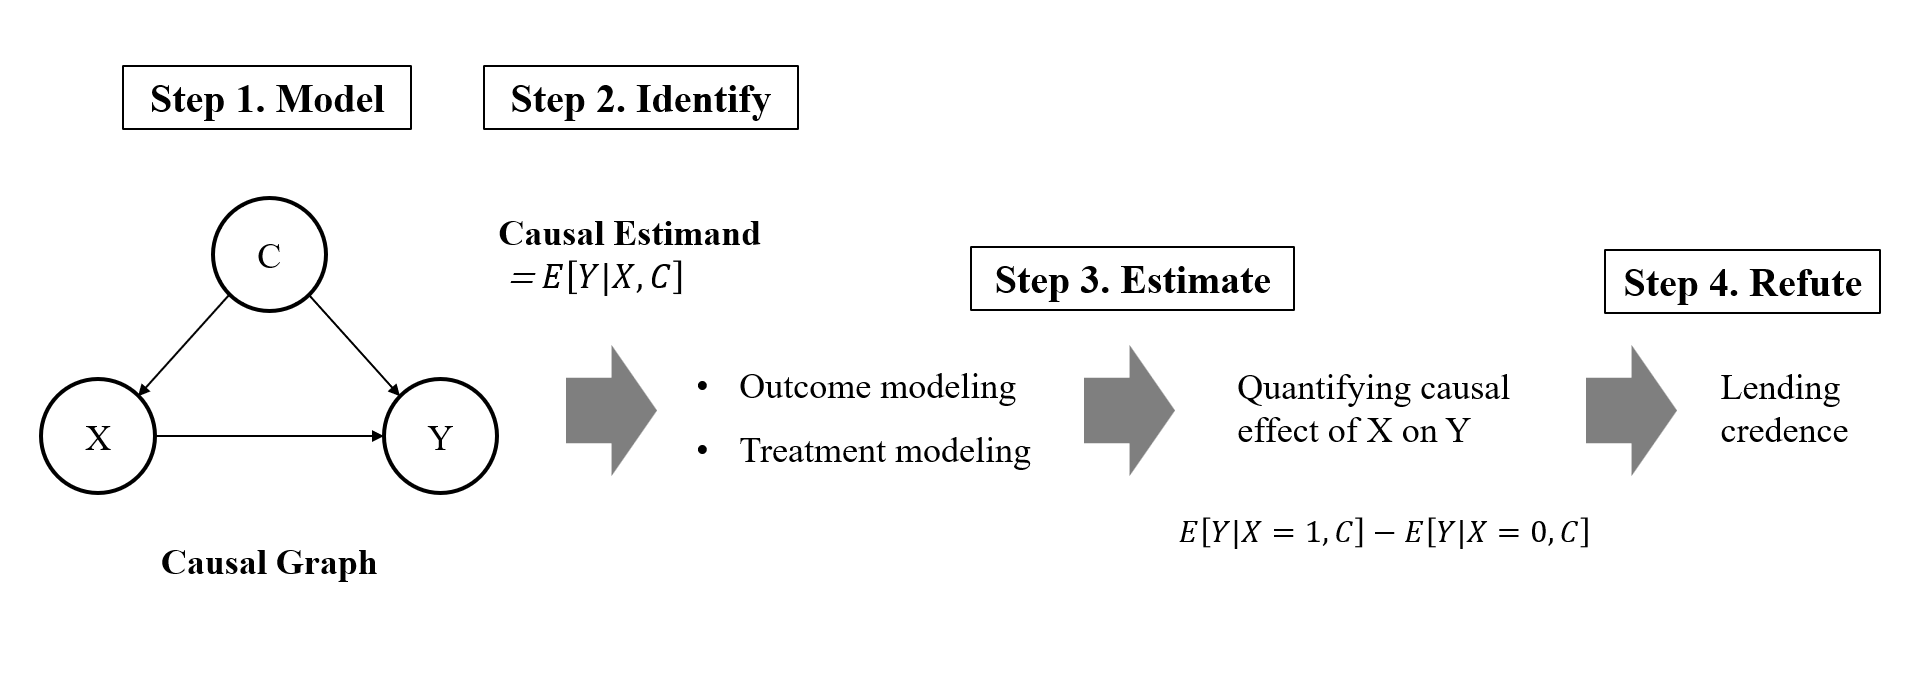

### 1단계. 모형화 (Model)

In [ ]:
np.random.seed(1000)

In [ ]:
df = pd.DataFrame(columns=['Y', 'X', 'C'])

SAMPLE_SIZE = 1000

df['C'] = np.random.random(SAMPLE_SIZE)
df['X'] = np.where(df['C'] + np.random.random(SAMPLE_SIZE)>1, 1, 0)
df['Y'] = 0.7*df['X'] + 0.2*df['C'] + np.random.random(SAMPLE_SIZE)

df.head()

In [ ]:
# 처치군 (X=1)과 대조군 (X=0) (Treatment Group vs Control Group)
df.groupby(['X'])['X'].count()

In [ ]:
# 데이터 생성 과정을 나타내는 인과 그래프 정의 (Define the causal graph that represents the data generation process)
# GML(그래프 모델링 언어; Graph Modelling Language) 사용 (Using GML)
gml_graph = """
graph [
    directed 1
    
    node [id "X" label "X"]    
    node [id "Y" label "Y"]
    node [id "C" label "C"]
    
    edge [source "C" target "X"]
    edge [source "C" target "Y"]
    edge [source "X" target "Y"]
]
"""

In [ ]:
causal_graph = dowhy.CausalModel(
    data=df,
    treatment='X',
    outcome='Y',
    graph=gml_graph
)

causal_graph.view_model()

### 2단계. 식별 (Identify)

**주어진 인과 그래프는 교란변수 C를 통제하면 X가 Y에 미치는 인과효과를 추정할 수 있음을 보여줍니다.**

### 3단계. 추정 (Estimate)

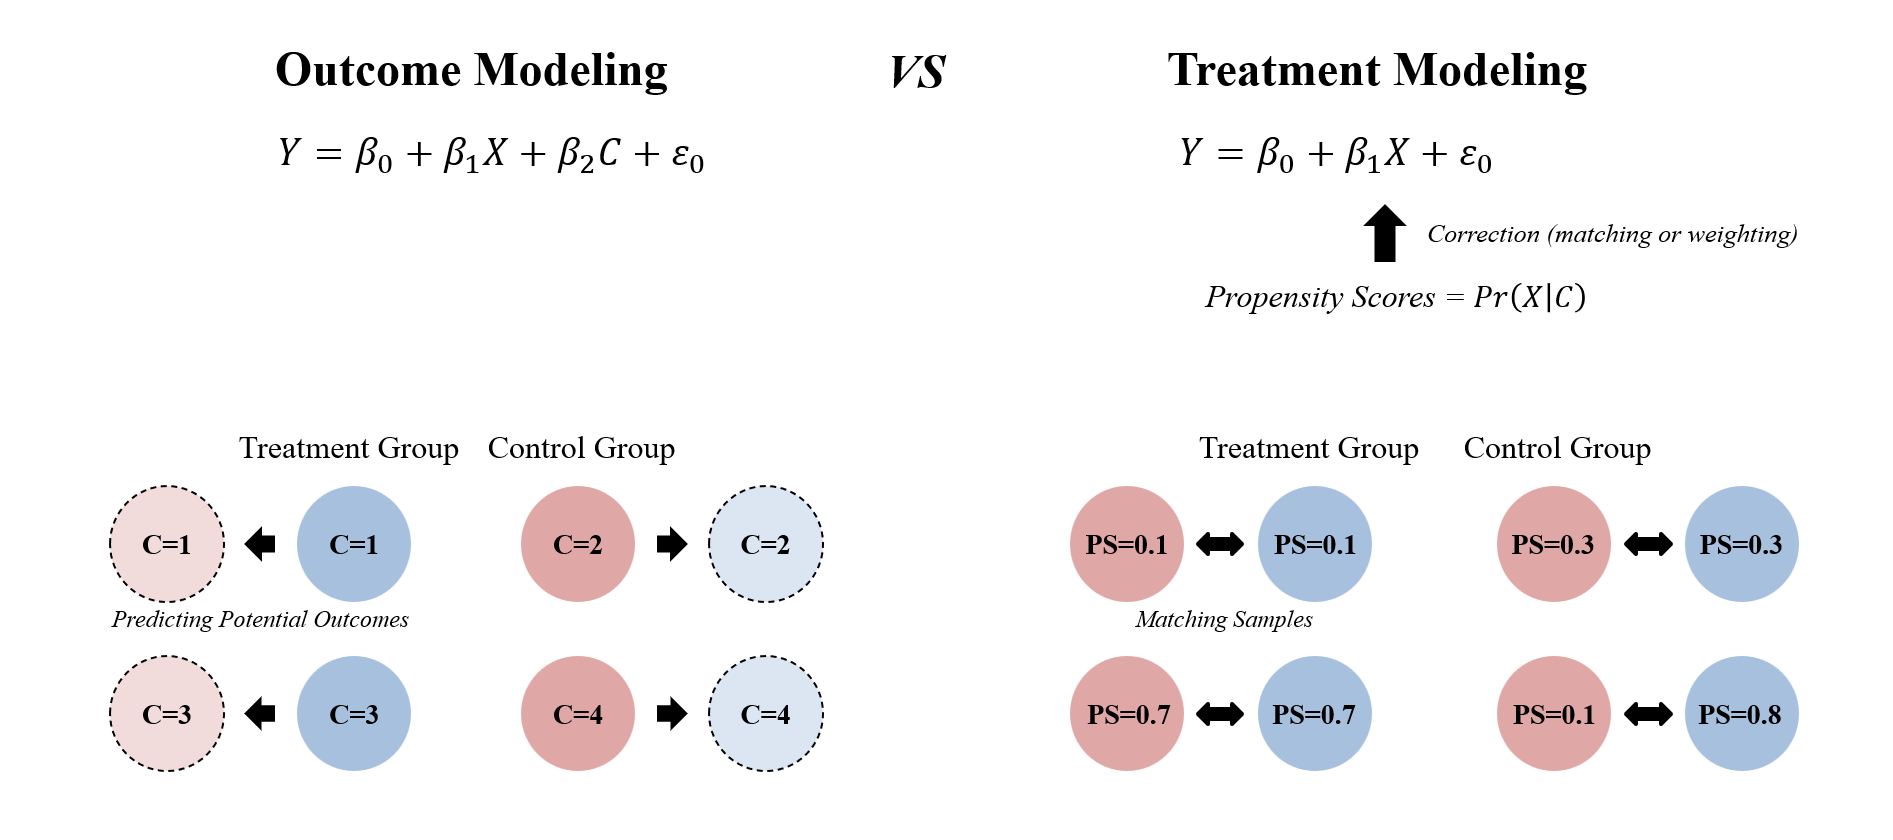

#### (1) 결과 모형화 (Outcome Modeling): 선형 회귀를 이용한 주변부 표준화 (Marginal standardization using linear regression)

In [ ]:
# Y를 X와 C에 회귀 (Regress Y on X and C)
model_LR = LinearRegression()
model_LR.fit(df[['X', 'C']], df['Y'])

In [ ]:
# 모든 관측치에 처치를 하거나 하지 않은 반사실적 표본 (Counterfactual samples with all units receiving treatment or no treatment)
df_1 = df.copy()
df_1['X'] = 1

df_0 = df.copy()
df_0['X'] = 0

In [ ]:
# 모든 표본에 대해 X=1 또는 X=0일 때의 잠재적 결과 예측 (Predict potential outcomes when X = 1 or X = 0 for all samples)
Y_pred_LR_1 = model_LR.predict(df_1[['X', 'C']])
Y_pred_LR_0 = model_LR.predict(df_0[['X', 'C']])

In [ ]:
# 표본 전체에서 처치 및 대조 조건의 잠재적 결과 차이를 평균내어 ATE 계산 (Compute ATE by averaging the differences between the potential outcomes under treatment and control across the sample)
np.mean(Y_pred_LR_1 - Y_pred_LR_0)

#### (2) 처치 모형화 (Treatment Modeling): 역확률 가중치 (Inverse probability weighting)

In [ ]:
# X의 이진 분류 (Binary classification for X)
model_logit = LogisticRegression()
model_logit.fit(df[['C']], df['X'])

In [ ]:
# 성향점수 계산 (Computing propensity scores)
propensity = model_logit.predict_proba(df[['C']])
propensity

In [ ]:
# 성향점수의 역확률 가중치 계산 (Computing inverse weights of propensity score)
df['propensity_score'] = propensity[:, 1]
df['inverse_weight'] = np.where(df['X']==1, 1/df['propensity_score'], 1/(1-df['propensity_score']))
df

In [ ]:
# 역확률 가중치를 적용한 회귀 (Regression with inverse weights)

model_weightedReg = LinearRegression()
model_weightedReg.fit(df[['X']], df['Y'], sample_weight=df['inverse_weight'])

In [ ]:
# 표본 전체에서 처치 및 대조 조건의 잠재적 결과 차이를 평균내어 ATE 계산 (Compute ATE by averaging the differences between the potential outcomes under treatment and control across the sample)

Y_pred_weightedReg_1 = model_weightedReg.predict(df_1[['X']])
Y_pred_weightedReg_0 = model_weightedReg.predict(df_0[['X']])

np.mean(Y_pred_weightedReg_1 - Y_pred_weightedReg_0)

## 2부. 인과 ML이 필요한 이유 (Why is Causal ML Necessary?)

### 쟁점 1. 복잡한 인과 그래프에서의 식별 (Issue 1. Identification in complex causal graphs)

In [ ]:
np.random.seed(1000)

In [ ]:
SAMPLE_SIZE = 1000

S = np.random.random(SAMPLE_SIZE)
Q = 0.2*S + np.random.random(SAMPLE_SIZE)
X = np.where(Q + np.random.random(SAMPLE_SIZE)>1, 1, 0)
C = 0.1*S + 0.3*X + np.random.random(SAMPLE_SIZE)
Y = 0.7*X + 0.11*Q + 0.32*S + 0.5*C + np.random.random(SAMPLE_SIZE)
P = 0.43*X + 0.21*Y + np.random.random(SAMPLE_SIZE)

df_complex = pd.DataFrame(np.vstack([S, Q, X, Y, P, C]).T, columns=['S', 'Q', 'X', 'Y', 'P', 'C'])
df_complex.head()

In [ ]:
gml_graph_complex = """
graph [
    directed 1

    node [id "S" label "S"]
    node [id "Q" label "Q"]
    node [id "X" label "X"]
    node [id "Y" label "Y"]
    node [id "P" label "P"]
    node [id "C" label "C"]
    
    edge [source "S" target "Q"]
    edge [source "Q" target "X"]
    edge [source "S" target "C"]
    edge [source "X" target "C"]
    edge [source "X" target "Y"]
    edge [source "Q" target "Y"]
    edge [source "S" target "Y"]
    edge [source "C" target "Y"]
    edge [source "X" target "P"]
    edge [source "Y" target "P"]
]
"""

In [ ]:
causal_graph_complex = dowhy.CausalModel(
    data=df_complex,
    treatment='X',
    outcome='Y',
    graph=gml_graph_complex
)

causal_graph_complex.view_model()

In [ ]:
# 모든 관측치에 처치를 하거나 하지 않은 반사실적 표본 (Counterfactual samples with all units receiving treatment or no treatment)
df_complex_1 = df_complex.copy()
df_complex_1['X'] = 1

df_complex_0 = df_complex.copy()
df_complex_0['X'] = 0

In [ ]:
# 과소식별 모형 (Under-identified model)

# 결과 모형화 (Outcome modeling)
model_LR_underId = LinearRegression()
model_LR_underId.fit(df_complex[['X']], df_complex['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_LR_underId_1 = model_LR_underId.predict(df_complex_1[['X']])
Y_pred_LR_underId_0 = model_LR_underId.predict(df_complex_0[['X']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_LR_underId_1 - Y_pred_LR_underId_0)

In [ ]:
# 과잉식별 모형 (Over-identified model)

# 결과 모형화 (Outcome modeling)
model_LR_overId = LinearRegression()
model_LR_overId.fit(df_complex[['X', 'C', 'P', 'Q', 'S']], df_complex['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_LR_overId_1 = model_LR_overId.predict(df_complex_1[['X', 'C', 'P', 'Q', 'S']])
Y_pred_LR_overId_0 = model_LR_overId.predict(df_complex_0[['X', 'C', 'P', 'Q', 'S']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_LR_overId_1 - Y_pred_LR_overId_0)

In [ ]:
# 올바르게 식별된 모형 (전체 인과효과; Right-identified model, total causal effect)

# 결과 모형화 (Outcome modeling)
model_LR_rightId = LinearRegression()
model_LR_rightId.fit(df_complex[['X', 'Q']], df_complex['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_LR_rightId_1 = model_LR_rightId.predict(df_complex_1[['X', 'Q']])
Y_pred_LR_rightId_0 = model_LR_rightId.predict(df_complex_0[['X', 'Q']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_LR_rightId_1 - Y_pred_LR_rightId_0)

In [ ]:
# 올바르게 식별된 모형 (직접 인과효과; Right-identified model, direct causal effect)

# 결과 모형화 (Outcome modeling)
model_LR_rightId_direct = LinearRegression()
model_LR_rightId_direct.fit(df_complex[['X', 'Q', 'C']], df_complex['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_LR_rightId_direct_1 = model_LR_rightId_direct.predict(df_complex_1[['X', 'Q', 'C']])
Y_pred_LR_rightId_direct_0 = model_LR_rightId_direct.predict(df_complex_0[['X', 'Q', 'C']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_LR_rightId_direct_1 - Y_pred_LR_rightId_direct_0)

> **Q1. 복잡한 인과 그래프에서 인과효과(causal effect)를 추정하기 위한 유효한 조건화 집합(valid conditioning sets)을 모두 어떻게 식별할 수 있을까요?**

### 쟁점 2. 비선형성 (Issue 2. Nonlinearity)

In [ ]:
np.random.seed(1000)

In [ ]:
df_nonlinear = pd.DataFrame(columns=['Y', 'X', 'C'])

SAMPLE_SIZE = 1000

df_nonlinear['C'] = np.random.random(SAMPLE_SIZE)
df_nonlinear['X'] = df_nonlinear['C'] + np.random.random(SAMPLE_SIZE)
df_nonlinear['Y'] = -2*df_nonlinear['X'] + df_nonlinear['X']*df_nonlinear['X'] + 0.2*df_nonlinear['C'] + + np.random.random(SAMPLE_SIZE)

df_nonlinear.head()

In [ ]:
# 비선형성 시각화 (Visualize nonlinearity)
import matplotlib.pyplot as plt

df_nonlinear['X_rounded'] = df_nonlinear['X'].round(2)
aggregated_Y = df_nonlinear.groupby('X_rounded')['Y'].mean().reset_index()        
plt.scatter(aggregated_Y['X_rounded'], aggregated_Y['Y'])

In [ ]:
# 모든 관측치에 처치를 하거나 하지 않은 반사실적 표본 (Counterfactual samples with all units receiving treatment or no treatment)
df_nonlinear_1 = df_nonlinear.copy()
df_nonlinear_1['X'] = 1

df_nonlinear_0 = df_nonlinear.copy()
df_nonlinear_0['X'] = 0

In [ ]:
# 결과 모형화 (Outcome modeling)
model_LR_nonlinear = LinearRegression()
model_LR_nonlinear.fit(df_nonlinear[['X', 'C']], df_nonlinear['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_LR_nonlinear_1 = model_LR_nonlinear.predict(df_nonlinear_1[['X', 'C']])
Y_pred_LR_nonlinear_0 = model_LR_nonlinear.predict(df_nonlinear_0[['X', 'C']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_LR_nonlinear_1 - Y_pred_LR_nonlinear_0)

> **Q2. 변수 사이의 복잡한 비선형 관계(nonlinear relationships)를 어떻게 학습할 수 있을까요?**

### 쟁점 3. 머신러닝은 본질적으로 인과추론을 위해 설계된 것이 아닐 수 있음 (Issue 3. Machine learning may not be inherently designed for causal inference)

#### 머신러닝을 이용한 결과 모형화 (Outcome modeling using machine learning; random forest regressor)

In [ ]:
df_complex.head()

In [ ]:
# 결과 모형화 (Outcome modeling)
model_RF = RandomForestRegressor( )
model_RF.fit(df_complex[['X', 'Q']], df_complex['Y'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_RF_1 = model_RF.predict(df_complex_1[['X', 'Q']])
Y_pred_RF_0 = model_RF.predict(df_complex_0[['X', 'Q']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_RF_1 - Y_pred_RF_0)

> **Q3. 처치(treatment)에 불균형(imbalance)이 있다면 어떻게 될까요?**

In [ ]:
np.random.seed(1000)

In [ ]:
df_complex['X2'] = np.where(df_complex['C'] + np.random.random(SAMPLE_SIZE)>2.1, 1, 0)
df_complex['Y2'] = 0.7*df_complex['X2'] + 0.2*df_complex['C'] + np.random.random(SAMPLE_SIZE)

# 처치군 (X=1)과 대조군 (X=0) (Treatment Group vs Control Group)
df_complex.groupby(['X2'])['X2'].count()

In [ ]:
# 모든 관측치에 처치를 하거나 하지 않은 반사실적 표본 (Counterfactual samples with all units receiving treatment or no treatment)
df_complex_1['X2'] = 1
df_complex_0['X2'] = 0

In [ ]:
# 결과 모형화 (Outcome modeling)
model_RF_unbal = RandomForestRegressor( )
model_RF_unbal.fit(df_complex[['X2', 'Q']], df_complex['Y2'])

# 잠재적 결과 예측 (Potential outcome prediction)
Y_pred_RF_unbal_1 = model_RF_unbal.predict(df_complex_1[['X2', 'Q']])
Y_pred_RF_unbal_0 = model_RF_unbal.predict(df_complex_0[['X2', 'Q']])

# 인과효과 추정 (Causal effect estimation)
np.mean(Y_pred_RF_unbal_1 - Y_pred_RF_unbal_0)

> **Q4. 인과추론(causal inference)에 맞게 머신러닝(machine learning)을 어떻게 조정할 수 있을까요?**

## 3부. 인과 ML을 위한 PyWhy 생태계 (PyWhy Ecosystem for Causal ML)

PyWhy는 인과추론에 머신러닝을 적용하기 위한 생태계를 제공하며, 모형화부터 식별과 추정까지 엔드투엔드 과정을 지원합니다. 이는 엔드투엔드 분석 워크플로(Model–Identify–Estimate–Refute)에 맞춰진 세 개의 상호 연결된 패키지로 구성되며, 공통 API를 통해 통합됩니다:
- (1) DoWhy: 인과 그래프 모형화 및 식별 (Causal Graph Modeling and Identification)
- (2) EconML: 추정 (Estimation)
- (3) causal-learn: 인과발견 (Causal Discovery)

자세한 내용은 https://www.pywhy.org/learn/developer-resources.html 를 참고하세요.

In [ ]:
np.random.seed(1000)

In [ ]:
SAMPLE_SIZE = 1000

S = np.random.random(SAMPLE_SIZE)
Q = 0.2*S + np.random.random(SAMPLE_SIZE)
X = np.where(Q + np.random.random(SAMPLE_SIZE)>1, 1, 0)
C = 0.1*S + 0.3*X + np.random.random(SAMPLE_SIZE)
Y = 0.7*X + 0.11*Q + 0.32*S + 0.5*C + np.random.random(SAMPLE_SIZE)
P = 0.43*X + 0.21*Y + np.random.random(SAMPLE_SIZE)

df_pywhy = pd.DataFrame(np.vstack([S, Q, X, Y, P, C]).T, columns=['S', 'Q', 'X', 'Y', 'P', 'C'])
df_pywhy.head()

### 1단계. 모형화 (Model)

In [ ]:
gml_graph_pywhy = """
graph [
    directed 1

    node [id "S" label "S"]
    node [id "Q" label "Q"]
    node [id "X" label "X"]
    node [id "Y" label "Y"]
    node [id "P" label "P"]
    node [id "C" label "C"]
    
    edge [source "S" target "Q"]
    edge [source "Q" target "X"]
    edge [source "S" target "C"]
    edge [source "X" target "C"]
    edge [source "X" target "Y"]
    edge [source "Q" target "Y"]
    edge [source "S" target "Y"]
    edge [source "C" target "Y"]
    edge [source "X" target "P"]
    edge [source "Y" target "P"]
]
"""

In [ ]:
causal_graph_pywhy = dowhy.CausalModel(
    data=df_pywhy,
    treatment='X',
    outcome='Y',
    graph=gml_graph_pywhy
)

causal_graph_pywhy.view_model()

### 2단계. 식별 (Identify)

DoWhy는 do-calculus를 적용하여 인과 식별을 가능하게 합니다.

In [ ]:
estimand = causal_graph_pywhy.identify_effect()
print(estimand)

### 3단계. 추정 (Estimate)

PyWhy 생태계에서는 CausalModel(DoWhy 제공)이 EconML에서 제공하는 인과 머신러닝 모델을 내부적으로 활용할 수 있습니다.

EconML은 Microsoft Research의 ALICE 팀이 개발한 오픈 소스 소프트웨어입니다. 새로운 모델이 지속적으로 추가·관리되고 있으므로, 사용 가능한 머신러닝 모델과 사용 방법에 대한 자세한 내용은 공식 문서(https://econml.azurewebsites.net)를 참고하는 것을 강력히 권장합니다.

#### 벤치마크: 선형 회귀 (Benchmark: Linear Regression)

In [ ]:
estimate_linearRegression = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.linear_regression')

print(f'Estimate of causal effect (linear regression): {estimate_linearRegression.value}')

#### 인과 ML 모델 (Causal ML models)
인과 ML 모델은 임의의 머신러닝 모델을 기본 학습기(base learner)로 사용할 수 있는 인과효과 추정 프레임워크입니다.

#### (1) 메타 학습자 (Meta-Learner)

In [ ]:
# S-학습자 (S-Learner)
estimate_SLearner = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.metalearners.SLearner',
    method_params={
        'init_params': {
            'overall_model': RandomForestRegressor()
        }
    })

print(f'Causal effect estimate (S-Learner): {estimate_SLearner.value}')

In [ ]:
# T-학습자 (T-Learner)
estimate_TLearner = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.metalearners.TLearner',
    method_params={
        'init_params': {
            'models': [
                RandomForestRegressor(),
                RandomForestRegressor()
            ]
        }
    })

print(f'Causal effect estimate (T-Learner): {estimate_TLearner.value}')

In [ ]:
# X-학습자 (X-Learner)
estimate_XLearner = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.metalearners.XLearner',
    method_params={
        'init_params': {
            'models': [
                RandomForestRegressor(),
                RandomForestRegressor()
            ],
            'cate_models': [
                RandomForestRegressor(),
                RandomForestRegressor()
            ]
        }
    })

print(f'Causal effect estimate (X-Learner): {estimate_XLearner.value}')

#### (2) 이중 머신러닝 (Double Machine Learning; DML)
DML에서는 `auto` 옵션을 통해 모델을 자동으로 선택할 수 있습니다.

In [ ]:
estimate_DML = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.dml.DML',
    method_params={
        'init_params': {
            'model_y': RandomForestRegressor(),
            'model_t': RandomForestRegressor(),
            'model_final': LinearRegression(fit_intercept=False),
        }
    })

print(f'Causal effect estimate (Double Machine Learning): {estimate_DML.value}')

In [ ]:
estimate_DML = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.dml.DML',
    method_params={
        'init_params': {
            'model_y': 'auto',
            'model_t': 'auto',
            'model_final': LinearRegression(fit_intercept=False),
        }
    })

print(f'Causal effect estimate (Double Machine Learning): {estimate_DML.value}')

#### (3) 이중 강건 학습자 (Doubly Robust Learner; DRL)
DRL에서는 `auto` 옵션을 통해 모델을 자동으로 선택할 수 있습니다.

In [ ]:
estimate_DRL = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.dr.DRLearner',
    method_params={
        'init_params': {
            'model_propensity': LogisticRegression(),
            'model_regression': RandomForestRegressor()
        }
    })

print(f'Causal effect estimate (Doubly Robust Learner): {estimate_DRL.value}')

In [ ]:
estimate_DRL = causal_graph_pywhy.estimate_effect(
    identified_estimand=estimand,
    method_name='backdoor.econml.dr.DRLearner',
    method_params={
        'init_params': {
            'model_propensity': 'auto',
            'model_regression': 'auto'    
        }
    })

print(f'Causal effect estimate (Doubly Robust Learner): {estimate_DRL.value}')

### 4단계. 반증 (Refute)

사용 가능한 반증 방법은 https://www.pywhy.org/dowhy/v0.8/user_guide/effect_inference/refute.html# 를 참고하세요.
* `Add Random Common Cause`: 데이터셋에 독립적인 무작위 변수를 공통 원인으로 추가했을 때 추정값이 변하는가? (힌트: 변하지 않아야 합니다.)
* `Placebo Treatment`: 실제 처치 변수를 독립적인 무작위 변수로 대체하면 추정된 인과효과는 어떻게 되는가? (힌트: 효과가 0에 가까워져야 합니다.)
* `Dummy Outcome`: 실제 결과 변수를 독립적인 무작위 변수로 대체하면 추정된 인과효과는 어떻게 되는가? (힌트: 효과가 0에 가까워져야 합니다.)
* `Simulated Outcome`: 주어진 데이터셋과 가장 유사한 알려진 데이터 생성 과정에 기반한 시뮬레이션 데이터셋으로 교체하면 추정된 인과효과는 어떻게 되는가? (힌트: 데이터 생성 과정의 효과 모수와 일치해야 합니다.)
* `Add Unobserved Common Causes`: 처치 및 결과와 상관된 추가 공통 원인(교란변수)을 데이터셋에 넣었을 때 효과 추정값은 얼마나 민감하게 변하는가? (힌트: 지나치게 민감하지 않아야 합니다.)
* `Data Subsets Validation`: 주어진 데이터셋을 무작위로 선택한 부분집합으로 교체했을 때 추정된 효과가 유의하게 변하는가? (힌트: 변하지 않아야 합니다.)
* `Bootstrap Validation`: 주어진 데이터셋을 동일한 데이터셋에서 부트스트랩한 표본으로 교체했을 때 추정된 효과가 유의하게 변하는가? (힌트: 변하지 않아야 합니다.)

#### (1) 무작위 공통 원인 추가 (Add Random Common Cause)

In [ ]:
random_cause = causal_graph_pywhy.refute_estimate(
    estimand=estimand, 
    estimate=estimate_TLearner,
    method_name='random_common_cause'
)

In [ ]:
print(random_cause)

#### (2) 위약 처치 (Placebo Treatment)

In [ ]:
placebo_refuter = causal_graph_pywhy.refute_estimate(
    estimand=estimand, 
    estimate=estimate_TLearner,
    method_name='placebo_treatment_refuter',
    placebo_type='permute'
)

In [ ]:
print(placebo_refuter)

#### [DoWhy-EconML 튜토리얼 (DoWhy-EconML Tutorial)](https://www.pywhy.org/dowhy/v0.8/example_notebooks/tutorial-causalinference-machinelearning-using-dowhy-econml.html)에서 더 많은 실습 예제를 확인하세요.

## 4부. 인과발견 (Causal Discovery)

`causal-learn` 패키지는 PyWhy 생태계의 일부이며, (i) 제약조건 기반, (ii) 점수 기반, (iii) 함수 기반 방법을 포함한 인과발견 알고리즘을 제공합니다. 자세한 내용은 https://causal-learn.readthedocs.io 문서를 참고하세요.

### 설정 (Setup)

In [ ]:
np.random.seed(1000)

In [ ]:
SAMPLE_SIZE = 1000

S = np.random.random(SAMPLE_SIZE)
Q = 0.2*S + np.random.random(SAMPLE_SIZE)
X = 0.5*Q + np.random.random(SAMPLE_SIZE)
C = 0.1*S + 0.3*X + np.random.random(SAMPLE_SIZE)
Y = 0.7*X + 0.11*Q + 0.32*S + 0.5*C + np.random.random(SAMPLE_SIZE)
P = 0.43*X + 0.21*Y + np.random.random(SAMPLE_SIZE)

labels = ['S', 'Q', 'X', 'C', 'Y', 'P']
df_cd = pd.DataFrame(np.vstack([S, Q, X, C, Y, P]).T, columns=labels)
df_cd.head()

In [ ]:
# causal-learn은 NumPy 배열 형식의 입력 데이터를 필요로 합니다. (causal-learn requires input data in NumPy array format)
np_data = df_cd.to_numpy()

In [ ]:
gml_graph_cd = """
graph [
    directed 1

    node [id "S" label "S"]
    node [id "Q" label "Q"]
    node [id "X" label "X"]
    node [id "Y" label "Y"]
    node [id "P" label "P"]
    node [id "C" label "C"]
    
    edge [source "S" target "Q"]
    edge [source "Q" target "X"]
    edge [source "S" target "C"]
    edge [source "X" target "C"]
    edge [source "X" target "Y"]
    edge [source "Q" target "Y"]
    edge [source "S" target "Y"]
    edge [source "C" target "Y"]
    edge [source "X" target "P"]
    edge [source "Y" target "P"]
]
"""

In [ ]:
causal_graph_cd = dowhy.CausalModel(
    data=df_cd,
    treatment='X',
    outcome='Y',
    graph=gml_graph_cd
)

causal_graph_cd.view_model()

In [ ]:
# 인과 그래프 시각화 함수 (Function to visualize a causal graph)
from IPython.display import Image, display
from causallearn.utils.GraphUtils import GraphUtils
from causallearn.graph.Endpoint import Endpoint
import matplotlib.pyplot as plt
import networkx as nx
import os
import shutil

def view_graph(graph, labels):
    # Graphviz가 설치되어 있으면 기존의 고해상도 렌더링을 사용합니다. (Use the existing high-resolution rendering if Graphviz is installed.)
    pydot_graph = GraphUtils.to_pydot(graph, labels=labels)
    dot_path = shutil.which('dot')
    if dot_path is None:
        for candidate in ('/opt/homebrew/bin/dot', '/usr/local/bin/dot'):
            if os.path.isfile(candidate) and os.access(candidate, os.X_OK):
                dot_path = candidate
                break
    if dot_path is not None:
        display(Image(pydot_graph.create_png(prog=dot_path)))
        return

    # Graphviz(dot)가 없는 환경에서도 노트북이 중단되지 않도록 (Ensure the notebook does not stop when Graphviz(dot) is unavailable)
    # NetworkX + Matplotlib으로 causal-learn 그래프를 표시합니다. (Display the causal-learn graph with NetworkX + Matplotlib)
    print("Graphviz의 'dot'을 찾지 못해 Matplotlib으로 그래프를 표시합니다.")
    nodes = graph.get_nodes()
    node_labels = list(labels) if labels is not None else [node.get_name() for node in nodes]
    node_name = {node.get_name(): node_labels[i] for i, node in enumerate(nodes)}

    base_graph = nx.Graph()
    base_graph.add_nodes_from(node_labels)
    directed_edges = []
    bidirected_edges = []
    undirected_edges = []
    uncertain_edges = []

    for edge in graph.get_graph_edges():
        node1 = node_name[edge.get_node1().get_name()]
        node2 = node_name[edge.get_node2().get_name()]
        base_graph.add_edge(node1, node2)
        endpoint1 = edge.get_endpoint1()
        endpoint2 = edge.get_endpoint2()

        if endpoint1 == Endpoint.TAIL and endpoint2 == Endpoint.ARROW:
            directed_edges.append((node1, node2))
        elif endpoint1 == Endpoint.ARROW and endpoint2 == Endpoint.TAIL:
            directed_edges.append((node2, node1))
        elif endpoint1 == Endpoint.ARROW and endpoint2 == Endpoint.ARROW:
            bidirected_edges.append((node1, node2))
        elif endpoint1 == Endpoint.TAIL and endpoint2 == Endpoint.TAIL:
            undirected_edges.append((node1, node2))
        else:
            uncertain_edges.append((node1, node2))

    position = nx.spring_layout(base_graph, seed=42)
    plt.figure(figsize=(10, 7))
    nx.draw_networkx_nodes(base_graph, position, node_color='#D9EAF7', node_size=1800, edgecolors='#4C78A8')
    nx.draw_networkx_labels(base_graph, position, font_size=10)
    nx.draw_networkx_edges(base_graph, position, edgelist=undirected_edges, width=2, edge_color='#555555')
    nx.draw_networkx_edges(base_graph, position, edgelist=uncertain_edges, width=2, style='dashed', edge_color='#888888')
    nx.draw_networkx_edges(base_graph, position, edgelist=directed_edges, arrows=True, arrowstyle='-|>', arrowsize=22, width=2, edge_color='#1F77B4')
    nx.draw_networkx_edges(base_graph, position, edgelist=bidirected_edges, arrows=True, arrowstyle='<->', arrowsize=18, width=2, edge_color='#D62728')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

### 1. 제약조건 기반 방법: PC 알고리즘 (Constraint-based Methods: PC Algorithm)
제약조건 기반 방법은 일반적으로 하나의 인과 DAG가 아니라 완전 부분 방향 비순환 그래프(CPDAG)로 표현되는 마르코프 동치 클래스(Markov equivalence class)를 식별합니다. 남은 간선의 방향을 완전히 정하기 위해서는 추가 가정이나 개입 지식 또는 도메인 지식이 필요합니다.

In [ ]:
from causallearn.search.ConstraintBased.PC import pc

graph_pc = pc(np_data)
view_graph(graph_pc.G, labels)

### 2. 제약조건 기반 방법: FCI 알고리즘 (Constraint-based Methods: FCI Algorithm)
FCI 알고리즘은 잠재적 교란변수와 선택 편향이 있는 상황에서 하나의 인과 DAG가 아니라 부분 조상 그래프(PAG)로 표현되는 인과 그래프의 마르코프 동치 클래스(Markov equivalence class)를 식별합니다. 남은 간선 표식을 완전히 정하기 위해서는 추가 가정이나 개입 지식 또는 도메인 지식이 필요합니다.

In [ ]:
from causallearn.search.ConstraintBased.FCI import fci

graph_fci, edges = fci(np_data)
view_graph(graph_fci, labels)

### 3. 점수 기반 방법: GES 알고리즘 (Score-based Methods: GES Algorithm)
점수 기반 방법은 일반적으로 하나의 인과 DAG가 아니라 완전 부분 방향 비순환 그래프(CPDAG)로 표현되는 마르코프 동치 클래스(Markov equivalence class)를 식별합니다. 남은 간선의 방향을 완전히 정하기 위해서는 추가 가정이나 개입 지식 또는 도메인 지식이 필요합니다.

In [ ]:
from causallearn.search.ScoreBased.GES import ges

graph_ges = ges(np_data)
view_graph(graph_ges['G'], labels)

### 4. 함수 기반 방법: LiNGAM 기반 방법 (Function-based Methods: LiNGAM-based Methods)
조건부 독립성 검정에 의존하는 제약조건 기반 방법과 그래프 점수를 최적화하는 점수 기반 방법과 달리, LiNGAM(선형·비가우시안·비순환 모형; Linear, Non-Gaussian Acyclic Model) 기반 방법은 기저 구조함수와 비가우시안 잡음에 대한 가정을 활용하여 인과 그래프를 식별합니다.

In [ ]:
from causallearn.search.FCMBased import lingam

model_lingam = lingam.ICALiNGAM()
model_lingam.fit(np_data)

In [ ]:
from causallearn.search.FCMBased.lingam.utils import make_dot

make_dot(model_lingam.adjacency_matrix_, labels=labels)

**제약조건 기반 방법(Constraint-based methods)은 부분 방향 그래프(CPDAG; partially directed graph)를 반환하는 경우가 많지만, LiNGAM 기반 방법(LiNGAM-based methods)은 구조적 함수 가정(structural functional assumptions)하에서 완전히 방향성이 있는 인과 그래프(fully directed causal graph)를 식별합니다.**

In [ ]:
# 완전 그래프를 LinGAM의 DOT(그래프 설명 언어; graph description language) 형식으로 변환하는 함수 (Function to transform a complete graph from LinGAM into DOT graph format)
import graphviz
import networkx as nx

def make_graph(adjacency_matrix, labels=None):
    idx = np.abs(adjacency_matrix) > 0.01
    dirs = np.where(idx)
    d = graphviz.Digraph(engine='dot')
    names = labels if labels else [f'x{i}' for i in range(len(adjacency_matrix))]
    for name in names:
        d.node(name)
    for to, from_, coef in zip(dirs[0], dirs[1], adjacency_matrix[idx]):
        d.edge(names[from_], names[to], label=str(coef))
    return d

def str_to_dot(string):
    graph = string.strip().replace('\n', ';').replace('\t','')
    graph = graph[:9] + graph[10:-2] + graph[-1] # 문자열에서 불필요한 문자 제거 (Removing unnecessary characters from string)
    return graph

In [ ]:
# 유효한 DOT 형식 생성 (Obtain valid DOT format)
graph_dot = make_graph(model_lingam.adjacency_matrix_, labels=labels)

# graphviz 라이브러리의 입력 문자열을 유효한 DOT 그래프 형식으로 변환 (Convert input string from graphviz library to valid DOT graph format)
graph_lingam = str_to_dot(graph_dot.source)
graph_lingam

In [ ]:
# 인과 모형 정의 (Define causal model)
causal_graph_lingam = dowhy.CausalModel(
        data = df_complex,
        treatment='X',
        outcome='Y',
        graph=graph_lingam)

causal_graph_lingam.view_model()

#### [causal-learn 튜토리얼 (causal-learn Tutorial)](https://github.com/py-why/dowhy/blob/main/docs/source/example_notebooks/dowhy_causal_discovery_example.ipynb)에서 더 많은 실습 예제를 확인하세요.